In [303]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

In [304]:
y = -df.loc[df["segment_id"] == 1]["node_gpu_power_W"]
x = df.loc[df["segment_id"] == 1]["time_s"]

In [305]:
print(y.min(), y.max())

-4638.214199999999 -1551.4716000000003


In [306]:
from simses.battery import Battery
from simses.converter.converter import Converter
from simses.model.cell.skeleton_SCA import SCA3200
from simses.model.cell.sony_lfp import SonyLFP
from simses.model.converter.fix_efficiency import FixedEfficiency
from simses.model.converter.sinamics import SinamicsS120Fit

from hess import HybridController


In [307]:
def make_hess(tau):
    sc = Battery(
        cell=SCA3200(),
        circuit=(22,3),
        initial_states={
            "start_soc": 0.6,
            "start_T": 25.0,
        },
    )

    bat = Battery(
        cell=SonyLFP(),
        circuit=(16,20),
        initial_states={
            "start_soc": 0.6,
            "start_T": 25.0,
        },
    )

    battery_converter = Converter(
        loss_model=FixedEfficiency(1.0),
        max_power=20e3,
        storage=bat,
    )

    supercap_converter = Converter(
        loss_model=FixedEfficiency(1.0),
        max_power=20e3,
        storage=sc,
    )

    return HybridController(
        battery_branch=battery_converter,
        supercap_branch=supercap_converter,
        tau=tau,
        p_slow_init=y[0],
    )

In [308]:
def simulate(hess, x, y):
    dt = np.diff(x)

    log = {
        "battery_power": [],
        "supercap_power": [],
        "battery_soc": [],
        "supercap_soc": [],

        "battery_converter_loss": [],
        "battery_storage_loss": [],

        "supercap_converter_loss": [],
        "supercap_storage_loss": [],
    }

    for p_request, step_dt in zip(y[1:], dt):
        hess.step(p_request, step_dt)

        log["battery_power"].append(
            hess.battery_branch.state.power
        )
        log["supercap_power"].append(
            hess.supercap_branch.state.power
        )

        log["battery_soc"].append(
            hess.battery_branch.storage.state.soc
        )
        log["supercap_soc"].append(
            hess.supercap_branch.storage.state.soc
        )

        log["battery_converter_loss"].append(
            hess.battery_branch.state.loss
        )
        log["battery_storage_loss"].append(
            hess.battery_branch.storage.state.loss
        )

        log["supercap_converter_loss"].append(
            hess.supercap_branch.state.loss
        )
        log["supercap_storage_loss"].append(
            hess.supercap_branch.storage.state.loss
        )

    return log

In [309]:
taus = [0.001, 0.1, 0.5, 1, 2, 5, 10, 20, 100, 1_000]

results = {}

for tau in taus:
    hess = make_hess(tau)
    results[tau] = simulate(hess, x, y)

In [310]:
def summarize(log, dt, p_request):
    dt = np.asarray(dt)

    p_bat = np.asarray(log["battery_power"])
    p_sc = np.asarray(log["supercap_power"])

    bat_conv_loss = np.asarray(log["battery_converter_loss"])
    bat_storage_loss = np.asarray(log["battery_storage_loss"])

    sc_conv_loss = np.asarray(log["supercap_converter_loss"])
    sc_storage_loss = np.asarray(log["supercap_storage_loss"])

    soc_bat = np.asarray(log["battery_soc"])
    soc_sc = np.asarray(log["supercap_soc"])

    # ---- Energy throughput ----

    bat_throughput_Wh = (
        np.sum(np.abs(p_bat) * dt) / 3600
    )

    sc_throughput_Wh = (
        np.sum(np.abs(p_sc) * dt) / 3600
    )

    total_throughput_Wh = (
        bat_throughput_Wh + sc_throughput_Wh
    )

    # ---- Loss energies ----

    bat_converter_loss_Wh = (
        np.sum(bat_conv_loss * dt) / 3600
    )

    bat_storage_loss_Wh = (
        np.sum(bat_storage_loss * dt) / 3600
    )

    sc_converter_loss_Wh = (
        np.sum(sc_conv_loss * dt) / 3600
    )

    sc_storage_loss_Wh = (
        np.sum(sc_storage_loss * dt) / 3600
    )

    battery_loss_Wh = (
        bat_converter_loss_Wh
        + bat_storage_loss_Wh
    )

    supercap_loss_Wh = (
        sc_converter_loss_Wh
        + sc_storage_loss_Wh
    )

    total_loss_Wh = (
        battery_loss_Wh
        + supercap_loss_Wh
    )

    # ---- Useful comparison metric ----

    loss_fraction = (
        total_loss_Wh / total_throughput_Wh
        if total_throughput_Wh > 0
        else np.nan
    )

    return {
        "battery_throughput_Wh": bat_throughput_Wh,
        "supercap_throughput_Wh": sc_throughput_Wh,

        "battery_converter_loss_Wh": bat_converter_loss_Wh,
        "battery_storage_loss_Wh": bat_storage_loss_Wh,

        "supercap_converter_loss_Wh": sc_converter_loss_Wh,
        "supercap_storage_loss_Wh": sc_storage_loss_Wh,

        "battery_loss_Wh": battery_loss_Wh,
        "supercap_loss_Wh": supercap_loss_Wh,
        "total_loss_Wh": total_loss_Wh,

        "loss_fraction_pct": 100 * loss_fraction,

        "battery_soc_swing":
            np.max(soc_bat) - np.min(soc_bat),

        "supercap_soc_swing":
            np.max(soc_sc) - np.min(soc_sc),
    }

In [311]:
dt = np.diff(x)

summary = pd.DataFrame(
    [
        {
            "tau_s": tau,
            **summarize(
                results[tau],
                dt,
                y[1:],
            ),
        }
        for tau in taus
    ]
).set_index("tau_s")

summary[
    [
        "battery_throughput_Wh",
        "supercap_throughput_Wh",
        "battery_storage_loss_Wh",
        "supercap_storage_loss_Wh",
        "total_loss_Wh",
        "loss_fraction_pct",
    ]
].round(3)

,battery_throughput_Wh,supercap_throughput_Wh,battery_storage_loss_Wh,supercap_storage_loss_Wh,total_loss_Wh,loss_fraction_pct
tau_s,,,,,,
0.001,123.312,0.000,5.840,0.000,5.840,4.736
0.100,123.312,1.576,5.830,0.000,5.830,4.668
0.500,123.409,11.874,5.683,0.004,5.687,4.204
1.000,123.630,23.485,5.449,0.012,5.461,3.712
2.000,124.145,37.984,5.115,0.024,5.139,3.170
5.000,125.517,50.651,4.876,0.036,4.911,2.788
10.000,127.407,54.867,4.948,0.039,4.987,2.736
20.000,130.954,57.273,5.225,0.040,5.266,2.798
100.000,153.397,66.448,7.197,0.046,7.243,3.295


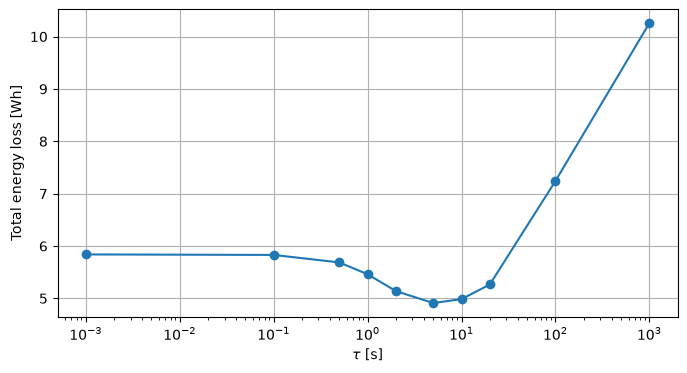

In [312]:
plt.figure(figsize=(8, 4))

plt.semilogx(
    summary.index,
    summary["total_loss_Wh"],
    marker="o",
)

plt.xlabel(r"$\tau$ [s]")
plt.ylabel("Total energy loss [Wh]")
plt.grid()
plt.show()

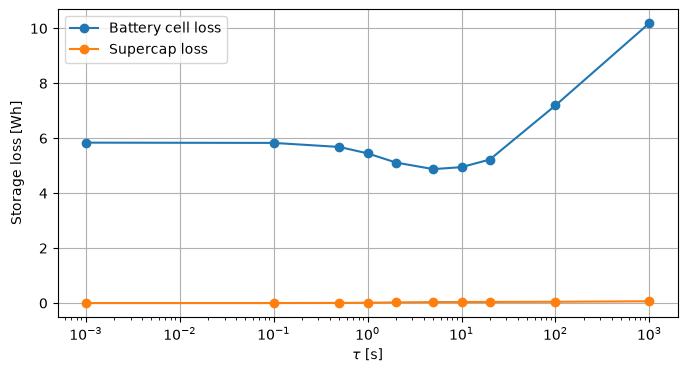

In [313]:
plt.figure(figsize=(8, 4))

plt.semilogx(
    summary.index,
    summary["battery_storage_loss_Wh"],
    marker="o",
    label="Battery cell loss",
)

plt.semilogx(
    summary.index,
    summary["supercap_storage_loss_Wh"],
    marker="o",
    label="Supercap loss",
)

plt.xlabel(r"$\tau$ [s]")
plt.ylabel("Storage loss [Wh]")
plt.grid()
plt.legend()
plt.show()

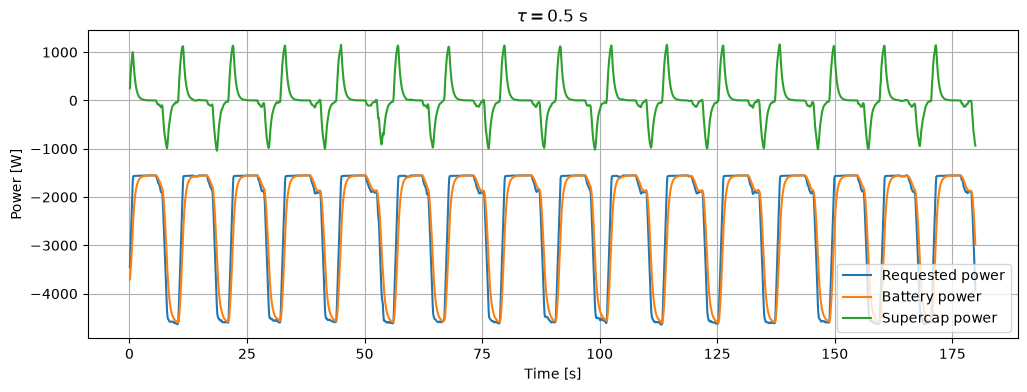

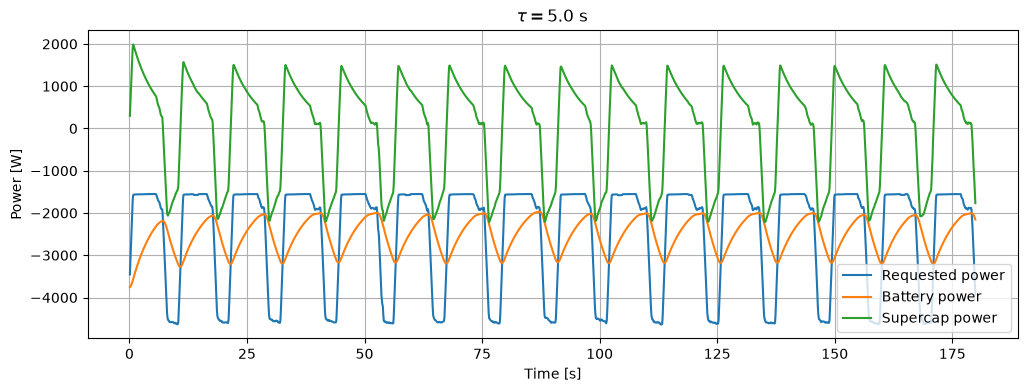

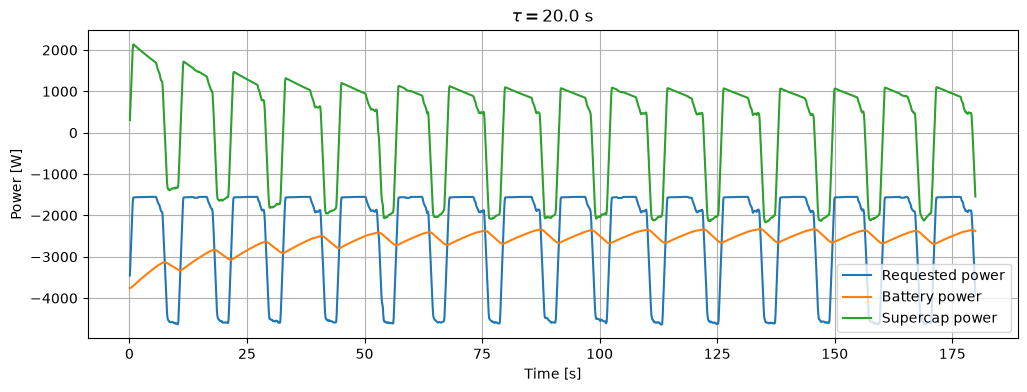

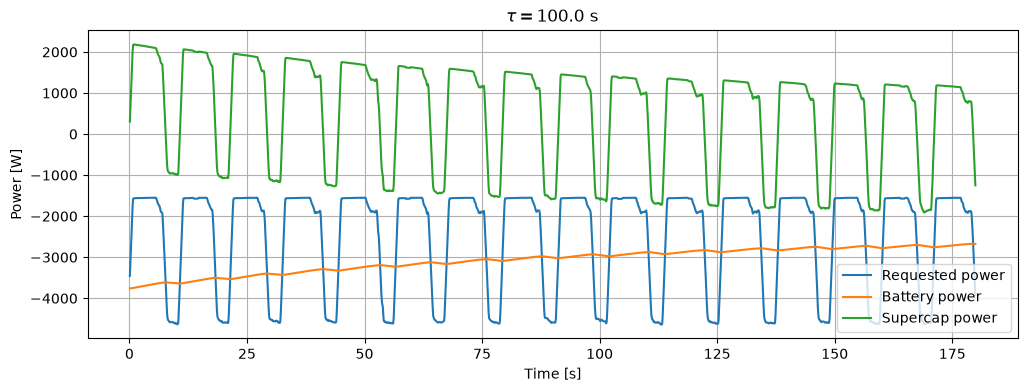

In [315]:
taus_to_plot = [0.5, 5.0, 20.0, 100.0]

for tau in taus_to_plot:
    log = results[tau]

    p_bat = np.asarray(log["battery_power"])
    p_sc = np.asarray(log["supercap_power"])

    plt.figure(figsize=(12, 4))

    plt.plot(
        x[1:],
        y[1:],
        label="Requested power",
        linewidth=1.5,
    )

    plt.plot(
        x[1:],
        p_bat,
        label="Battery power",
    )

    plt.plot(
        x[1:],
        p_sc,
        label="Supercap power",
    )

    plt.title(rf"$\tau = {tau}$ s")
    plt.xlabel("Time [s]")
    plt.ylabel("Power [W]")
    plt.grid()
    plt.legend()
    plt.show()

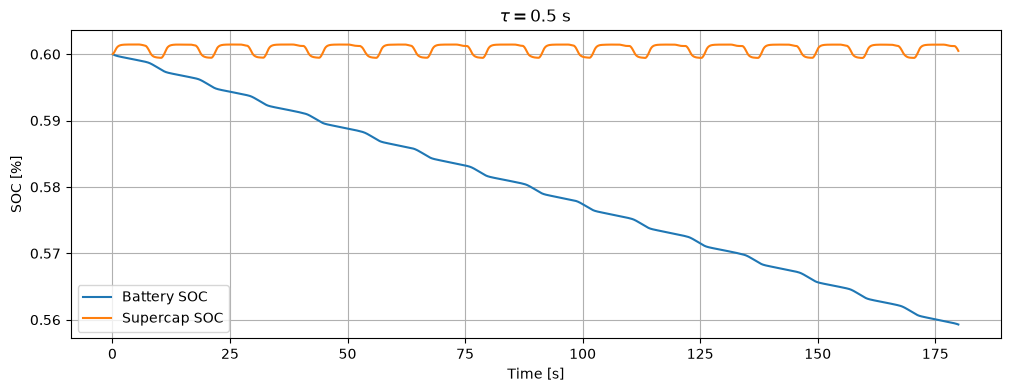

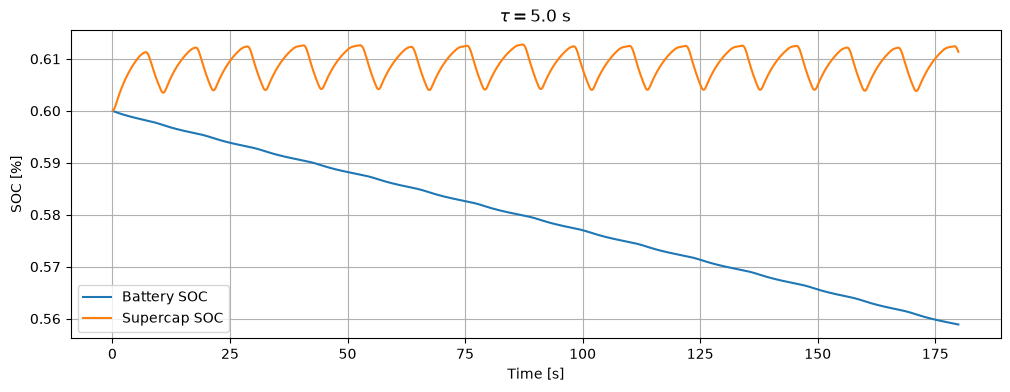

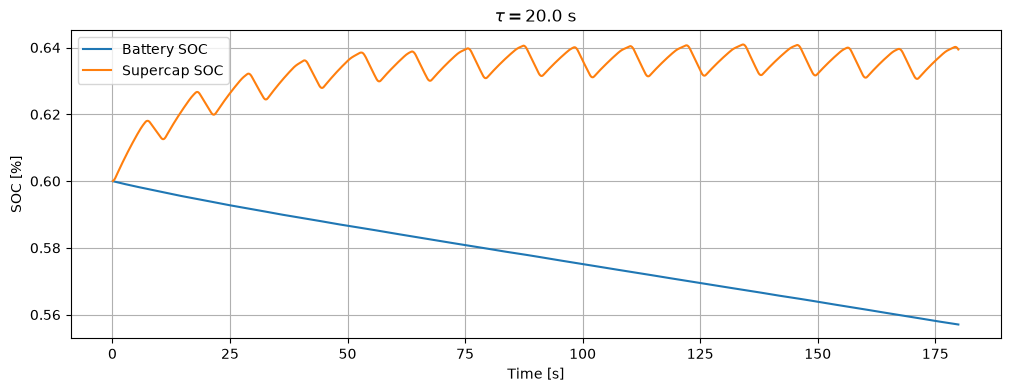

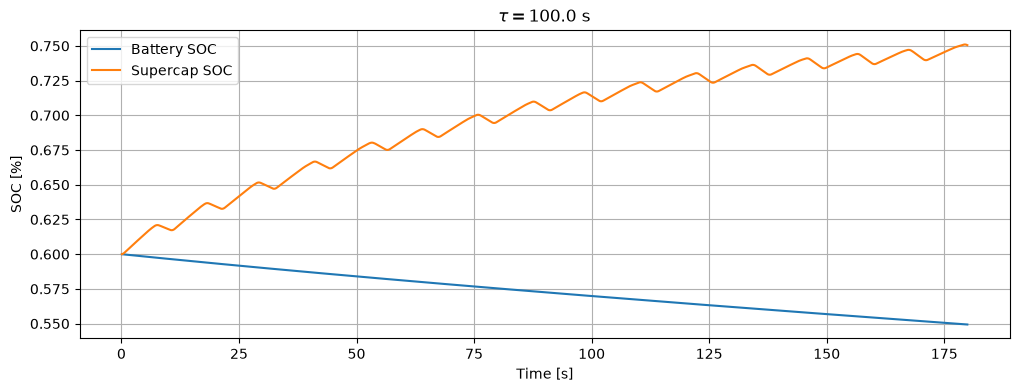

In [322]:
taus_to_plot = [0.5, 5.0, 20.0, 100.0]

for tau in taus_to_plot:
    log = results[tau]

    p_bat = np.asarray(log["battery_soc"])
    p_sc = np.asarray(log["supercap_soc"])

    plt.figure(figsize=(12, 4))

    plt.plot(
        x[1:],
        p_bat,
        label="Battery SOC",
    )

    plt.plot(
        x[1:],
        p_sc,
        label="Supercap SOC",
    )

    plt.title(rf"$\tau = {tau}$ s")
    plt.xlabel("Time [s]")
    plt.ylabel("SOC [%]")
    plt.grid()
    plt.legend()
    plt.show()